# S8 · Robustness and sensitivity analyses

Code: `code/si/S8_robustness.R`. Each block repeats the main model under
one change: filtered tokens, another filtering threshold, another
treatment of the nomination limit, subsamples by classroom size, sex or
grade, temporal controls, a lagged placebo, and other ways of measuring
rank.

For the regression tables, † denotes p \< 0.10, \* p \< 0.05, \*\* p \<
0.01, and \*\*\* p \< 0.001.

In [ ]:
here::i_am("notebooks/si/S8_robustness.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
library(igraph)
library(patchwork)
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads    <- read_csv(here("data", "generated", "analysis_dyads.csv"),    show_col_types = FALSE)
students <- read_csv(here("data", "generated", "analysis_students.csv"), show_col_types = FALSE)

dyads <- dyads %>%
  mutate(class_round = paste(class_id, round, sep = "_"),
         mutual = as.integer(friendship == "Mutual"))

save_si_figure <- function(plot, name, width, height) {
  ggsave(here("output", "figures", "si", paste0(name, ".pdf")), plot, width = width, height = height)
  ggsave(here("output", "figures", "si", paste0(name, ".png")), plot, width = width, height = height, dpi = 300)
}

# The preferred model (sender + classroom-by-round FE, SE by classroom) for
# any outcome and right-hand side. Returns NULL when it cannot be estimated.
preferred_model <- function(data, outcome = "coop_gap", rhs = "rank_gap",
                            fixed_effects = "sender_id + class_round") {
  data <- data %>% mutate(across(any_of(c("sender_id", "class_id", "class_round", "round")), as.factor))
  quiet_felm(as.formula(paste(outcome, "~", rhs, "|", fixed_effects, "| 0 | class_id")), data)
}

# Coefficient, SE and p of one term. NA = "not estimable" (n.e.): the model
# failed, the SE is not finite, or fewer than 10 residual degrees of freedom
# remain after the fixed effects (felm's df, which is also capped at the
# number of classrooms - 1).
term_estimate <- function(model, term = "rank_gap") {
  if (is.null(model) || model$df < 10) return(tibble(estimate = NA_real_, se = NA_real_, p_value = NA_real_))
  ct <- quiet_summary(model)$coefficients
  se_col <- if ("Cluster s.e." %in% colnames(ct)) "Cluster s.e." else "Std. Error"
  if (!term %in% rownames(ct) || !is.finite(ct[term, se_col]))
    return(tibble(estimate = NA_real_, se = NA_real_, p_value = NA_real_))
  tibble(estimate = ct[term, "Estimate"], se = ct[term, se_col], p_value = ct[term, "Pr(>|t|)"])
}

## 8.1 Filtered tokens (Tables S25–S30, Figure S25)

These regressions use the Cooperation GAP for pairs in which both
transfers survive the null-model filter. Standard errors are in
parentheses.

### Estimates by friendship group

#### Table S25. All dyads

In [ ]:
# 8.1 The main tables again, with the null-model filtered Cooperation GAP
# (only pairs where both transfers survive the filter; see 01_build_measures.R)
filtered <- dyads %>% filter(!is.na(coop_gap_filtered))
cat("Decisions with both directions kept by the filter:", nrow(filtered), "\n")
## Decisions with both directions kept by the filter: 4590

fe_filtered_all    <- fe_progression(filtered, outcome = "coop_gap_filtered")
fe_filtered_non    <- fe_progression(filter(filtered, friendship == "Non-friends"), outcome = "coop_gap_filtered")
fe_filtered_mutual <- fe_progression(filter(filtered, friendship == "Mutual"), outcome = "coop_gap_filtered")
fe_filtered_pooled <- fe_progression(filter(filtered, friendship %in% c("Non-friends", "Mutual")),
                                     outcome = "coop_gap_filtered", formula_rhs = "rank_gap * mutual")

regression_table(fe_filtered_all,    terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,3.093***,3.093***,3.178***,3.168***,3.426***
,(0.197),(0.469),(0.458),(0.457),(0.503)
Observations,"4,590","4,590","4,590","4,590","4,590"
R2,0.051,0.051,0.288,0.289,0.338
Adj. R2,0.051,0.042,0.134,0.125,-0.049


#### Table S26. Non-friends

In [ ]:
regression_table(fe_filtered_non,    terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,3.260***,3.260***,3.223***,3.183***,3.412***
,(0.233),(0.462),(0.496),(0.492),(0.654)
Observations,"3,302","3,302","3,302","3,302","3,302"
R2,0.056,0.056,0.331,0.333,0.413
Adj. R2,0.056,0.043,0.129,0.118,-0.085


#### Table S27. Mutual friends

In [ ]:
regression_table(fe_filtered_mutual, terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,-0.593,-0.593,-0.367,-0.030,5.167
,(0.529),(0.607),(1.018),(0.978),(3.463)
Observations,548,548,548,548,548
R2,0.002,0.002,0.755,0.798,0.956
Adj. R2,0.000,-0.087,0.174,0.122,0.114


#### Table S28. Pooled non-friends and mutual friends

The interaction tests whether the slope differs for mutual friends.

In [ ]:
regression_table(fe_filtered_pooled, terms = c("rank_gap", "mutual", "rank_gap:mutual"))

row,(1),(2),(3),(4),(5)
rank_gap,3.260***,3.260***,3.261***,3.242***,3.393***
,(0.225),(0.462),(0.462),(0.460),(0.543)
mutual,-0.000,-0.000,-0.161,-0.184,-0.504*
,(0.217),(0.000),(0.126),(0.130),(0.210)
rank_gap:mutual,-3.853***,-3.853***,-3.767***,-3.778***,-4.194***
,(0.720),(0.731),(0.731),(0.736),(0.824)
Observations,"3,850","3,850","3,850","3,850","3,850"
R2,0.052,0.052,0.303,0.305,0.373
Adj. R2,0.051,0.040,0.120,0.110,-0.083


### One-sided friendship nominations

#### Table S29. Lower to higher rank

In [ ]:
filtered_asymmetric <- filtered %>%
  filter(friendship == "Sender declares") %>%
  mutate(high_to_low = as.integer(rank_gap >= 0))

fe_filtered_lh <- fe_progression(filter(filtered_asymmetric, high_to_low == 0), outcome = "coop_gap_filtered")

regression_table(fe_filtered_lh, terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,4.905***,4.165*,0.685,3.022,n.e.
,(1.332),(1.694),(2.408),(3.380),
Observations,254,254,254,254,254
R2,0.051,0.229,0.822,0.915,n.e.
Adj. R2,0.047,0.075,0.223,0.021,n.e.


#### Table S29. Higher to lower rank

This group includes ties in Social Rank, following the rule in the main
analysis.

Specifications (4) and (5) are not estimable for this filtered sample.
The fixed effects absorb all variation in its 116 observations.

In [ ]:
filtered_high_to_low <- filter(filtered_asymmetric, high_to_low == 1)
fe_filtered_hl <- fe_progression(filtered_high_to_low, outcome = "coop_gap_filtered")

# A saturated fixed-effects design leaves no variation for the rank gap.
fixed_effects_4 <- model.matrix(~ factor(class_id) + factor(sender_id) + factor(round),
                               data = filtered_high_to_low)
fixed_effects_5 <- model.matrix(~ factor(sender_id) + factor(class_round),
                               data = filtered_high_to_low)
if (qr(fixed_effects_4)$rank == nrow(filtered_high_to_low)) fe_filtered_hl["(4)"] <- list(NULL)
if (qr(fixed_effects_5)$rank == nrow(filtered_high_to_low)) fe_filtered_hl["(5)"] <- list(NULL)

regression_table(fe_filtered_hl, terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,0.138,2.706,2.680,n.e.,n.e.
,(2.389),(2.839),(4.458),,
Observations,116,116,116,n.e.,n.e.
R2,0.000,0.407,0.990,n.e.,n.e.
Adj. R2,-0.009,0.079,0.830,n.e.,n.e.


#### Table S30. Direct contrast between directions

The contrast is the higher-to-lower slope minus the lower-to-higher
slope. The models use 370 directed decisions from 44 classrooms. The
table reports classroom-clustered standard errors, 95% confidence
intervals, and restricted wild-cluster bootstrap p-values (999 draws).
The two specifications without fixed effects coincide and are shown in
one row.

In [ ]:
# Table S30: H-to-L minus L-to-H slope on the current filtered sample.
contrast_data <- filtered_asymmetric %>%
  mutate(across(c(sender_id, class_id, class_round, round),
                ~ interaction(.x, high_to_low, drop = TRUE), .names = "{.col}_direction"),
         across(c(sender_id, class_id, class_round, round), factor))

contrast_fe <- list(
  "None" = character(),
  "Classroom" = "class_id",
  "Sender + classroom" = c("sender_id", "class_id"),
  "Sender + classroom + round" = c("sender_id", "class_id", "round"),
  "Sender + classroom-by-round" = c("sender_id", "class_round")
)

contrast_models <- function(effects, separate) {
  has_fe <- length(effects) > 0L
  if (has_fe && separate) effects <- paste0(effects, "_direction")
  fe <- if (has_fe) paste(effects, collapse = " + ") else "0"
  base <- if (has_fe && separate) "rank_gap" else "rank_gap + high_to_low"
  as_formula <- function(rhs) as.formula(paste("coop_gap_filtered ~", rhs, "|", fe, "| 0 | class_id"))
  list(full = as_formula(paste(base, "+ rank_gap:high_to_low")), restricted = as_formula(base))
}

filtered_contrast_row <- function(effects, separate, draws = 999L) {
  formulas <- contrast_models(effects, separate)
  full <- quiet_felm(formulas$full, contrast_data)
  terms <- c("rank_gap", "rank_gap:high_to_low")
  if (is.null(full) || full$N <= full$p) return(tibble(estimable = FALSE))
  b <- coef(full)[terms]
  V <- vcov(full)[terms, terms, drop = FALSE]
  if (any(!is.finite(b)) || any(!is.finite(V)) || V[2, 2] <= 0) return(tibble(estimable = FALSE))

  difference <- unname(b[2])
  se <- sqrt(V[2, 2])
  t_obs <- difference / se
  # Use the 45 classrooms in the experiment as the reference for cluster
  # inference, as in the SI. Bootstrap weights use the 44 observed clusters.
  df <- n_distinct(dyads$class_id) - 1L
  classes <- unique(contrast_data$class_id)
  restricted <- quiet_felm(formulas$restricted, contrast_data)
  residual <- drop(residuals(restricted))
  fitted <- contrast_data$coop_gap_filtered - residual

  set.seed(123)
  t_star <- map_dbl(seq_len(draws), function(draw) {
    weights <- setNames(sample(c(-1, 1), length(classes), replace = TRUE), classes)
    sample_data <- contrast_data %>%
      mutate(coop_gap_filtered = fitted + residual * weights[as.character(class_id)])
    fit <- quiet_felm(formulas$full, sample_data)
    if (is.null(fit)) return(NA_real_)
    unname(coef(fit)[terms[2]]) / sqrt(vcov(fit)[terms[2], terms[2]])
  })
  tibble(estimable = TRUE,
         lower_to_higher = unname(b[1]), lower_to_higher_se = sqrt(V[1, 1]),
         higher_to_lower = sum(b), higher_to_lower_se = sqrt(sum(V)),
         contrast = difference, contrast_se = se,
         ci_low = difference - qt(.975, df) * se, ci_high = difference + qt(.975, df) * se,
         cluster_p = 2 * pt(-abs(t_obs), df),
         wild_p = if (all(is.finite(t_star))) mean(abs(t_star) >= abs(t_obs)) else NA_real_)
}

table_s30 <- imap_dfr(contrast_fe, function(effects, label) {
  # With no fixed effects, direction-specific intercepts and the standard
  # interaction are the same model. Estimate it only once.
  if (length(effects) == 0L) {
    return(filtered_contrast_row(effects, FALSE) %>%
             mutate(fixed_effects = label, pooled_model = "Direction-specific intercepts / standard interaction",
                    .before = 1))
  }
  bind_rows(
    filtered_contrast_row(effects, TRUE) %>% mutate(pooled_model = "Direction-specific FE", .before = 1),
    filtered_contrast_row(effects, FALSE) %>% mutate(pooled_model = "Common FE interaction", .before = 1)
  ) %>% mutate(fixed_effects = label, .before = 1)
})

In [ ]:
format_slope <- function(b, se) if_else(is.na(b), "n.e.", sprintf("%.3f (%.3f)", b, se))
table_s30 %>%
  transmute(FE = fixed_effects, Model = pooled_model,
            `Lower to higher` = format_slope(lower_to_higher, lower_to_higher_se),
            `Higher to lower` = format_slope(higher_to_lower, higher_to_lower_se),
            Contrast = format_slope(contrast, contrast_se),
            `95% CI` = if_else(estimable, sprintf("[%.3f, %.3f]", ci_low, ci_high), "n.e."),
            `Cluster p` = round(cluster_p, 3), `Wild p` = round(wild_p, 3)) %>%
  knitr::kable()

FE,Model,Lower to higher,Higher to lower,Contrast,95% CI,Cluster p,Wild p
None,Direction-specific intercepts / standard interaction,4.905 (1.673),0.138 (2.195),-4.767 (2.674),"[-10.156, 0.623]",0.082,0.077
Classroom,Direction-specific FE,4.165 (1.695),2.706 (2.832),-1.458 (3.344),"[-8.198, 5.282]",0.665,0.687
Classroom,Common FE interaction,4.506 (1.652),1.061 (2.625),-3.446 (3.135),"[-9.764, 2.872]",0.278,0.283
Sender + classroom,Direction-specific FE,0.685 (2.409),2.680 (4.447),1.995 (4.932),"[-7.944, 11.934]",0.688,0.703
Sender + classroom,Common FE interaction,2.059 (2.599),2.303 (5.134),0.244 (5.952),"[-11.752, 12.240]",0.967,0.965
Sender + classroom + round,Direction-specific FE,n.e.,n.e.,n.e.,n.e.,NA,NA
Sender + classroom + round,Common FE interaction,3.982 (2.955),0.886 (5.868),-3.096 (6.676),"[-16.551, 10.359]",0.645,0.704
Sender + classroom-by-round,Direction-specific FE,n.e.,n.e.,n.e.,n.e.,NA,NA
Sender + classroom-by-round,Common FE interaction,n.e.,n.e.,n.e.,n.e.,NA,NA


### Filtered-token counterpart of Figure 3

The SI figure used a historical central-band filter. The 42 bin
summaries from that run are included in `data/raw/figure_s25_bins.csv`.
The regression tables use the global retention cutoff described above.

In [ ]:
# These bin summaries come from the historical central-band filter used for
# the SI figure. The regression tables above use the global retention cutoff.
s25_bins <- read_csv(here("data", "raw", "figure_s25_bins.csv"), show_col_types = FALSE)
s25_filtered_mean <- 4.946900760089924
s25_rows <- tribble(
  ~roman, ~label,                       ~group,            ~color,            ~y_min,
  "I",    "Non friends",                "Non-friends",     color_non_friends, -6,
  "II",   "Mutual friends",             "Mutual",          color_mutual,      -6,
  "III",  "Sender declared friendship", "Sender declares", color_asymmetric, -8.5
)

#### Individual panels

Panel A shows mean filtered tokens sent and received. Panel B compares
the observed and filtered Cooperation GAP. Each function is used once
per friendship group.

In [ ]:
s25_panel_theme <- theme_paper(base_size = 10) +
  theme(panel.border = element_rect(color = "grey70", linewidth = 0.45),
        axis.line = element_line(color = color_text, linewidth = 0.4),
        plot.title = element_text(face = "bold", size = 9),
        plot.margin = margin(2, 4, 2, 3))
s25_rank_labels <- tibble(
  gap = c(-0.62, 0.62),
  label = c("Receiver higher rank", "Sender higher rank")
)

In [ ]:
s25_token_panel <- function(filtered, color, mutual) {
  first_bin <- slice_min(filtered, gap, n = 1, with_ties = FALSE)
  ggplot(filtered, aes(gap)) +
    geom_vline(xintercept = 0, linetype = "dashed", color = color_text) +
    geom_hline(yintercept = s25_filtered_mean, linetype = "dashed", color = color_text) +
    geom_ribbon(aes(ymin = mean_received, ymax = mean_sent), fill = "#F0E5A8", alpha = 0.55) +
    geom_line(aes(y = mean_sent), color = color, linewidth = 1.15) +
    geom_line(aes(y = mean_received), color = color, linewidth = 1.15) +
    geom_point(aes(y = mean_sent), color = color, shape = 18, size = 3.3) +
    geom_point(aes(y = mean_received), color = color, shape = 15, size = 2.9) +
    geom_errorbar(aes(ymin = mean_sent - ci_sent, ymax = mean_sent + ci_sent),
                  color = color, width = 0.045, linewidth = 0.5) +
    geom_errorbar(aes(ymin = mean_received - ci_received, ymax = mean_received + ci_received),
                  color = color, width = 0.045, linewidth = 0.5) +
    annotate("text", x = first_bin$gap,
             y = pmin(first_bin$mean_sent + first_bin$ci_sent, 10.35) - 0.1 * mutual,
             label = "Sent", color = color, fontface = "bold", size = 2.45, vjust = -0.9) +
    annotate("text", x = first_bin$gap, y = pmax(first_bin$mean_received - first_bin$ci_received, 1.35),
             label = "Received", color = color, fontface = "bold", size = 2.45, vjust = 1.25) +
    geom_text(data = s25_rank_labels, aes(y = 0.15, label = label), fontface = "bold", size = 2.2) +
    scale_x_continuous(breaks = seq(-1, 1, 0.5)) +
    scale_y_continuous(breaks = c(0, 5, 10)) +
    coord_cartesian(xlim = c(-1.1, 1.1), ylim = c(-0.35, 11), expand = FALSE) +
    labs(title = "A", x = "Social Ranking GAP", y = "Tokens") +
    s25_panel_theme
}

In [ ]:
s25_gap_panel <- function(filtered, observed, color, y_min) {
  observed_color <- scales::alpha(color, 0.4)
  ggplot(filtered, aes(gap, mean_coop_gap)) +
    geom_vline(xintercept = 0, linetype = "dashed", color = color_text) +
    geom_hline(yintercept = 0, linetype = "dashed", color = color_text) +
    geom_line(data = observed, color = observed_color, linewidth = 0.8) +
    geom_errorbar(data = observed, aes(ymin = mean_coop_gap - ci_coop_gap,
                                       ymax = mean_coop_gap + ci_coop_gap),
                  color = observed_color, width = 0.045, linewidth = 0.35) +
    geom_point(data = observed, color = observed_color, size = 3.05) +
    geom_line(color = color, linewidth = 1.2) +
    geom_point(color = color, size = 3.5) +
    geom_errorbar(aes(ymin = mean_coop_gap - ci_coop_gap, ymax = mean_coop_gap + ci_coop_gap),
                  color = color, width = 0.045, linewidth = 0.5) +
    geom_text(data = s25_rank_labels, aes(gap, y_min + 0.15, label = label),
              inherit.aes = FALSE, fontface = "bold", size = 2.2) +
    annotate("text", x = c(0.48, 0.57), y = y_min + 1.45, label = c("Filtered", "Observed"),
             color = c(color, observed_color), hjust = c(1, 0), fontface = "bold", size = 2.45) +
    scale_x_continuous(breaks = seq(-1, 1, 0.5)) +
    scale_y_continuous(breaks = seq(-7.5, 5, 2.5)) +
    coord_cartesian(xlim = c(-1.1, 1.1), ylim = c(y_min - 0.35, 6.65), expand = FALSE) +
    labs(title = "B", x = "Social Ranking GAP", y = "Cooperation GAP\n[Received - Sent]") +
    s25_panel_theme
}

In [ ]:
s25_panels <- pmap(select(s25_rows, group, color, y_min), function(group, color, y_min) {
  filtered <- s25_bins %>% filter(.data$group == .env$group, version == "Filtered")
  observed <- s25_bins %>% filter(.data$group == .env$group, version == "Observed")
  list(A = s25_token_panel(filtered, color, group == "Mutual"),
       B = s25_gap_panel(filtered, observed, color, y_min))
}) %>% set_names(s25_rows$roman)

##### Row I. Non-friends

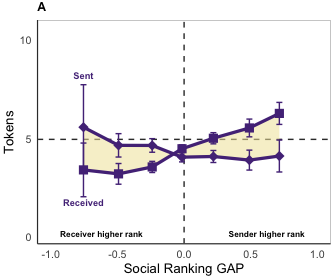

In [ ]:
s25_panels[["I"]]$A

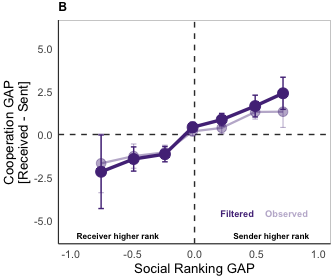

In [ ]:
s25_panels[["I"]]$B

##### Row II. Mutual friends

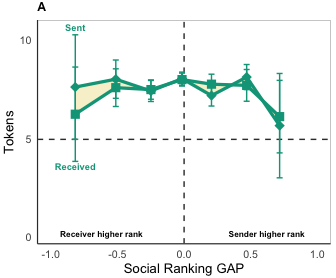

In [ ]:
s25_panels[["II"]]$A

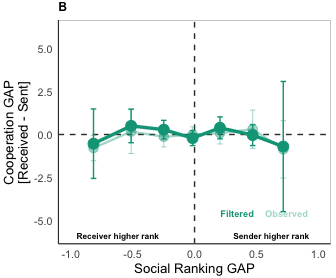

In [ ]:
s25_panels[["II"]]$B

##### Row III. Sender-declared friendships

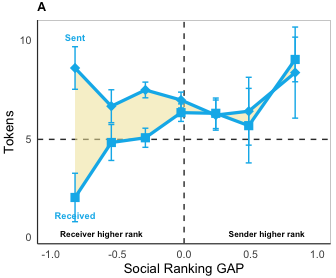

In [ ]:
s25_panels[["III"]]$A

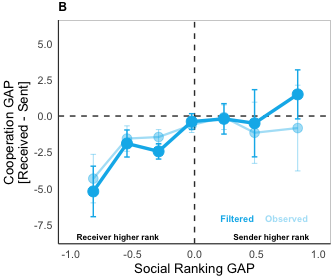

In [ ]:
s25_panels[["III"]]$B

#### From panels to rows

The colored headings and Roman numerals identify the friendship category
in each row. Here is the heading for non-friends on its own, followed by
the complete first row.

In [ ]:
s25_headers <- pmap(select(s25_rows, roman, label, color), friendship_row_header) %>%
  set_names(s25_rows$roman)

s25_assembled_rows <- map2(s25_headers, s25_panels, function(heading, panels) {
  heading / (panels$A | panels$B) + plot_layout(heights = c(0.095, 1))
})

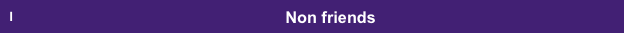

In [ ]:
s25_headers[["I"]]

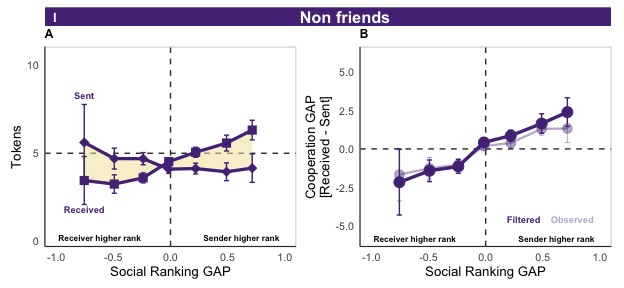

In [ ]:
s25_assembled_rows[["I"]]

#### Assembled Figure S25

Stack the three labeled rows to build the complete figure.

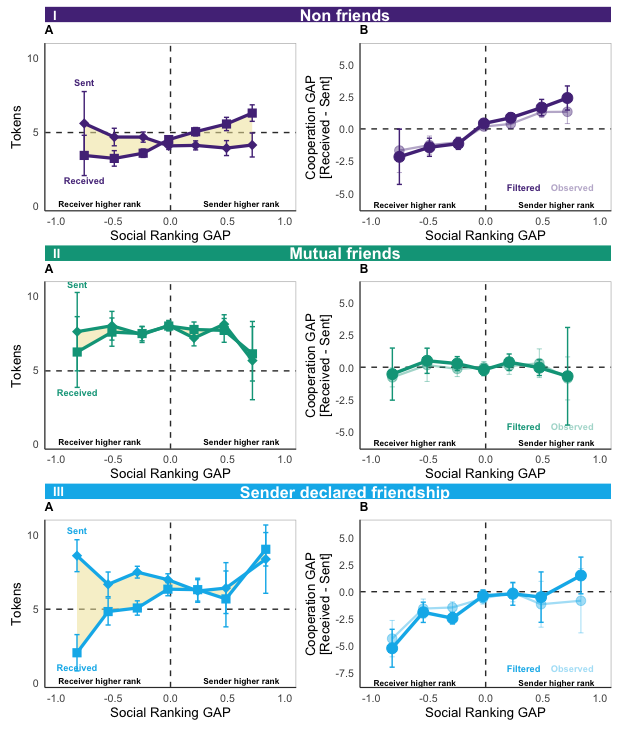

In [ ]:
figure_s25 <- wrap_plots(s25_assembled_rows, ncol = 1)
figure_s25

## 8.2 Filtering threshold and cutoff (Tables S31–S35)

“global” = one cutoff for all transfers (primary); “sender” = each child
keeps her own top share. n.e. (NA) marks models that cannot be estimated
(fewer than 10 residual degrees of freedom).

In [ ]:
# 8.2 Re-filter at other retention rates. "global": one cutoff for all
# transfers (the primary choice); "sender": each child keeps her own top
# share of transfers (ties and children with no variation are kept in full).
filter_at <- function(retention, scope = "global") {
  if (scope == "global") {
    cutoff <- sort(dyads$departure, decreasing = TRUE)[ceiling(retention * nrow(dyads))]
    kept <- dyads %>% mutate(keep = departure >= cutoff)
  } else {
    kept <- dyads %>%
      group_by(sender_id) %>%
      mutate(keep = departure >= quantile(departure, 1 - retention)) %>%
      ungroup()
  }
  reverse_keep <- kept %>% select(class_id, sender_id = receiver_id, receiver_id = sender_id, keep_reverse = keep)
  kept %>%
    left_join(reverse_keep, by = c("class_id", "sender_id", "receiver_id")) %>%
    mutate(coop_gap_p = if_else(keep & keep_reverse, coop_gap, NA_real_))
}

threshold_row <- function(retention, scope) {
  d <- filter_at(retention, scope)
  pairs <- d %>% filter(!is.na(coop_gap_p))
  all_fit    <- preferred_model(pairs, "coop_gap_p")
  non_fit    <- preferred_model(filter(pairs, friendship == "Non-friends"), "coop_gap_p")
  mutual_fit <- preferred_model(filter(pairs, friendship == "Mutual"), "coop_gap_p",
                                fixed_effects = "sender_id + class_id + round")
  pooled_fit <- preferred_model(filter(pairs, friendship %in% c("Non-friends", "Mutual")),
                                "coop_gap_p", rhs = "rank_gap * mutual")
  mutual_slope <- if (is.null(pooled_fit) || pooled_fit$df < 10) c(estimate = NA, se = NA, p = NA) else {
    b <- coef(pooled_fit); V <- vcov(pooled_fit); w <- c(1, 0, 1)
    est <- sum(w * b); se <- sqrt(drop(t(w) %*% V %*% w))
    c(estimate = est, se = se, p = 2 * pt(-abs(est / se), pooled_fit$df))
  }
  tibble(scope = scope, target = retention,
         transfers_retained = mean(d$keep), interactions = sum(d$keep),
         dyads_retained = mean(!is.na(d$coop_gap_p)), dyad_n = nrow(pairs),
         pooled_n = sum(pairs$friendship %in% c("Non-friends", "Mutual")),
         mutual_n = sum(pairs$friendship == "Mutual"),
         all = term_estimate(all_fit), non_friends = term_estimate(non_fit),
         mutual = term_estimate(mutual_fit),
         pooled_b1 = term_estimate(pooled_fit, "rank_gap"),
         pooled_b3 = term_estimate(pooled_fit, "rank_gap:mutual"),
         pooled_mutual_slope = mutual_slope[["estimate"]],
         pooled_mutual_slope_se = mutual_slope[["se"]],
         pooled_mutual_slope_p = mutual_slope[["p"]])
}

In [ ]:
retention_rates <- c(1, 0.7, 0.6, 0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1, 0.05)

threshold_sensitivity <- bind_rows(
  map_dfr(retention_rates, threshold_row, scope = "global"),
  map_dfr(retention_rates, threshold_row, scope = "sender")
) %>%
  unnest(c(all, non_friends, mutual, pooled_b1, pooled_b3), names_sep = "_")

threshold_sensitivity %>%
  select(scope, target, transfers_retained, interactions, dyad_n, mutual_n,
         all_estimate, non_friends_estimate, mutual_estimate, pooled_b3_estimate) %>%
  mutate(across(where(is.double), ~ round(.x, 2)))

scope,target,transfers_retained,interactions,dyad_n,mutual_n,all_estimate,non_friends_estimate,mutual_estimate,pooled_b3_estimate
global,1.00,1.00,17804,17804,1288,2.58,2.56,1.26,-1.67
global,0.70,0.70,12465,8874,838,3.14,3.21,0.64,-2.42
global,0.60,0.60,10684,6566,684,3.28,3.16,0.90,-2.77
global,0.50,0.50,8903,4590,548,3.43,3.41,-0.03,-4.19
global,0.40,0.40,7125,2966,424,3.61,3.38,-1.02,-3.31
global,0.30,0.30,5348,1774,310,2.64,1.77,-3.52,-1.11
global,0.25,0.25,4454,1276,262,2.10,-0.23,NA,1.87
global,0.20,0.20,3564,838,208,2.59,2.81,NA,1.40
global,0.15,0.15,2677,540,148,4.27,NA,NA,NA
global,0.10,0.10,1781,284,92,NA,NA,NA,NA


### Table S35. Sensitivity to the global filter by nomination direction

Each row repeats the asymmetric-friendship analysis with a different
share of transfers retained. A decision enters the filtered sample when
both directions of the exchange survive. The sender count shows how many
children still contribute at least two decisions. Standard errors are in
parentheses. n.e. marks specifications with fewer than 10 residual
degrees of freedom or without finite estimates. † p \< 0.10, \* p \<
0.05, \*\* p \< 0.01, \*\*\* p \< 0.001.

In [ ]:
# 8.2b The one-sided friendships (Sender declares) split by direction, along
# the same global retention grid and all five fixed-effects specifications.
# The sender count shows how much within-sender support remains.
asymmetric_specs <- c("No FE" = "0", "Classroom FE" = "class_id",
                      "Sender + classroom FE" = "sender_id + class_id",
                      "Sender + classroom + round FE" = "sender_id + class_id + round",
                      "Sender + classroom-by-round FE" = "sender_id + class_round")

asymmetric_row <- function(retention) {
  kept <- filter_at(retention, "global") %>%
    filter(friendship == "Sender declares", !is.na(coop_gap_p)) %>%
    mutate(direction = if_else(rank_gap < 0, "Low to high", "High to low"))
  kept %>%
    group_by(direction) %>%
    group_modify(function(d, key) {
      sender_counts <- count(d, sender_id)
      imap_dfr(asymmetric_specs, function(fe, spec) {
        # as in Table S29, column (1) uses conventional standard errors and
        # the fixed-effects columns cluster by classroom
        m <- if (fe == "0") quiet_felm(coop_gap_p ~ rank_gap | 0 | 0 | 0, d) else
          preferred_model(d, outcome = "coop_gap_p", fixed_effects = fe)
        est <- term_estimate(m)
        tibble(spec = spec, n = nrow(d), senders = nrow(sender_counts),
               senders_2plus = sum(sender_counts$n >= 2), est)
      })
    }) %>%
    ungroup() %>%
    mutate(retention = retention, .before = 1)
}

asymmetric_thresholds <- map_dfr(retention_rates, asymmetric_row) %>%
  mutate(spec = factor(spec, levels = names(asymmetric_specs)),
         direction = factor(direction, levels = c("Low to high", "High to low")))

format_asymmetric_thresholds <- function(nomination_direction) {
  asymmetric_thresholds %>%
    filter(direction == nomination_direction) %>%
    mutate(cell = if_else(is.na(estimate), "n.e.",
                          sprintf("%.2f%s (%.2f)", estimate, si_stars(p_value), se))) %>%
    select(retention, n, senders_2plus, spec, cell) %>%
    pivot_wider(names_from = spec, values_from = cell) %>%
    arrange(desc(retention)) %>%
    mutate(retention = if_else(retention == 1, "100% (observed)", scales::percent(retention))) %>%
    rename("Target" = retention, "Decisions" = n, "Senders with 2+ decisions" = senders_2plus)
}

#### Panel A. Lower-to-higher nominations

In [ ]:
knitr::kable(format_asymmetric_thresholds("Low to high"))

Target,Decisions,Senders with 2+ decisions,No FE,Classroom FE,Sender + classroom FE,Sender + classroom + round FE,Sender + classroom-by-round FE
100% (observed),894,253,2.59*** (0.71),2.64*** (0.71),3.07** (1.11),3.06* (1.18),-1.15 (4.17)
70%,464,119,3.70*** (0.99),3.43** (1.11),2.82† (1.65),2.91† (1.54),n.e.
60%,358,84,4.02*** (1.12),3.92** (1.22),2.61† (1.51),1.91 (2.48),n.e.
50%,254,53,4.90*** (1.33),4.16* (1.69),0.68 (2.41),3.02 (3.38),n.e.
40%,165,24,5.78*** (1.67),5.29** (1.88),1.78 (2.82),n.e.,n.e.
30%,114,14,3.86* (1.78),3.23 (2.50),-1.43 (4.46),n.e.,n.e.
25%,91,9,3.16 (2.03),-0.04 (2.26),n.e.,n.e.,n.e.
20%,61,5,5.47* (2.64),1.30 (3.56),n.e.,n.e.,n.e.
15%,44,2,7.23* (3.37),0.35 (5.85),n.e.,n.e.,n.e.
10%,24,1,7.70† (4.48),n.e.,n.e.,n.e.,n.e.


#### Panel B. Higher-to-lower nominations

In [ ]:
knitr::kable(format_asymmetric_thresholds("High to low"))

Target,Decisions,Senders with 2+ decisions,No FE,Classroom FE,Sender + classroom FE,Sender + classroom + round FE,Sender + classroom-by-round FE
100% (observed),406,81,-0.54 (1.33),0.21 (1.49),3.52 (3.67),4.77 (3.49),n.e.
70%,200,25,0.35 (1.96),0.48 (1.81),1.07 (5.97),n.e.,n.e.
60%,151,15,1.03 (2.16),1.14 (2.13),-5.97 (7.01),n.e.,n.e.
50%,116,7,0.14 (2.39),2.71 (2.84),n.e.,n.e.,n.e.
40%,84,5,3.16 (3.02),5.07 (4.80),n.e.,n.e.,n.e.
30%,56,4,3.07 (2.77),4.06 (4.52),n.e.,n.e.,n.e.
25%,48,3,4.04 (2.88),11.26** (3.51),n.e.,n.e.,n.e.
20%,26,1,1.73 (2.16),n.e.,n.e.,n.e.,n.e.
15%,15,1,4.97 (3.97),n.e.,n.e.,n.e.,n.e.
10%,6,0,n.e.,n.e.,n.e.,n.e.,n.e.


In [ ]:
# Asymmetric friendships by direction across the retention grid: (A) Social
# Rank GAP coefficient with 95% CI, three specifications; (B) data left.
# The figure shows the range where the samples still support estimation.
# Low-to-high in orange; retention shares on a reversed axis (100% =
# observed data). Each panel is built on its own and the two are stacked.
figure_range <- asymmetric_thresholds %>% filter(retention >= 0.4)
dodge <- position_dodge(width = 4)
direction_colors <- c("Low to high" = color_highlight, "High to low" = color_slate)
retention_labels <- function(x) if_else(x == 100, "100%\n(observed)", paste0(x, "%"))

coef_panel <- figure_range %>%
  filter(!is.na(estimate), spec %in% levels(spec)[1:3]) %>%
  ggplot(aes(100 * retention, estimate, color = direction)) +
  annotate("rect", xmin = 45, xmax = 55, ymin = -Inf, ymax = Inf, fill = "grey92") +   # the 50% filter
  geom_hline(yintercept = 0, linewidth = 0.3, color = "grey50") +
  geom_line(position = dodge, linewidth = 0.4, alpha = 0.6) +
  geom_errorbar(aes(ymin = estimate - 1.96 * se, ymax = estimate + 1.96 * se),
                width = 0, position = dodge, linewidth = 0.5) +
  geom_point(position = dodge, size = 1.8) +
  facet_wrap(~ spec, nrow = 1) +
  scale_x_reverse(breaks = c(100, 70, 60, 50, 40), labels = retention_labels) +
  scale_color_manual(values = direction_colors, name = NULL) +
  labs(title = "A. Social Rank GAP coefficient (95% CI)", x = NULL, y = "Coefficient") +
  theme_si() +
  theme(legend.position = "top", legend.justification = "left")

support_panel <- figure_range %>%
  distinct(retention, direction, n, senders_2plus) %>%
  pivot_longer(c(n, senders_2plus), names_to = "measure", values_to = "count") %>%
  mutate(measure = recode(measure, n = "Decisions retained",
                          senders_2plus = "Senders with 2+ retained decisions")) %>%
  ggplot(aes(100 * retention, count, color = direction)) +
  geom_line(linewidth = 0.5) +
  geom_point(size = 1.6) +
  facet_wrap(~ measure, nrow = 1, scales = "free_y") +
  scale_x_reverse(breaks = c(100, 70, 60, 50, 40), labels = retention_labels) +
  scale_y_continuous(limits = c(0, NA)) +
  scale_color_manual(values = direction_colors, guide = "none") +
  labs(title = "B. Data left for estimation", x = "Share of transfers retained by the filter", y = NULL) +
  theme_si()

Panel A: the coefficients.

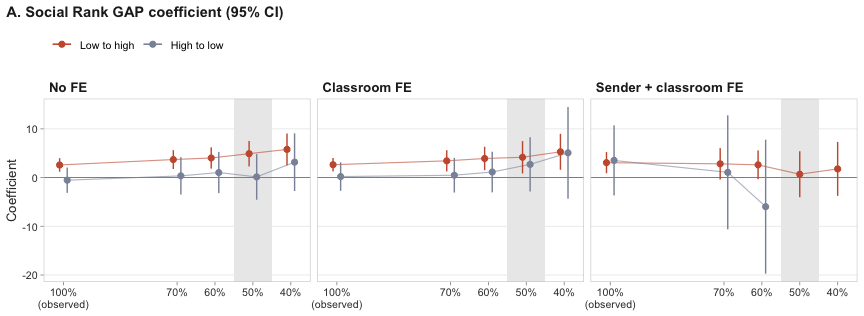

In [ ]:
coef_panel

Panel B: the data left at each retention share.

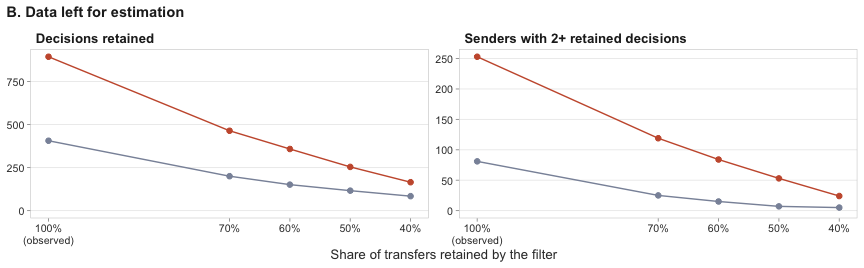

In [ ]:
support_panel

Both panels together:

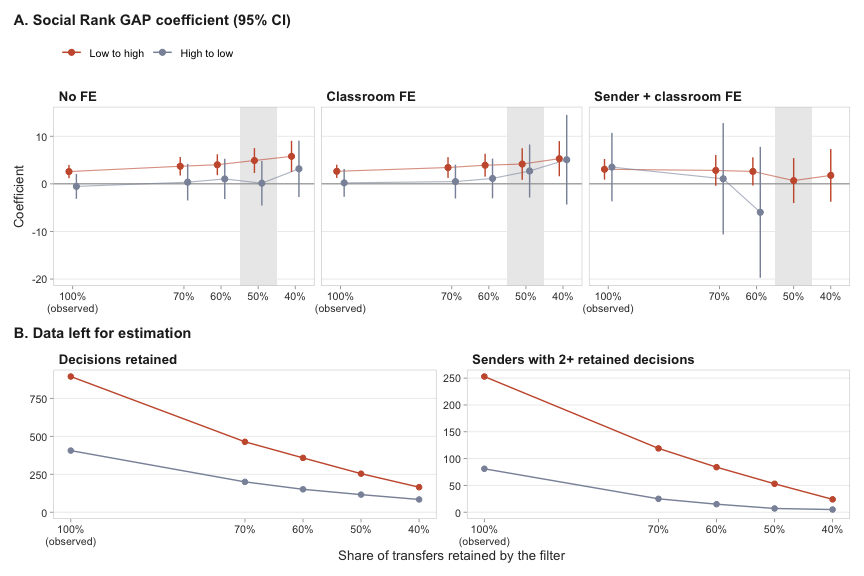

In [ ]:
figure_asymmetric_thresholds <- coef_panel / support_panel + plot_layout(heights = c(1.2, 1))
figure_asymmetric_thresholds

## 8.3 Nomination limit (Table S36, Figure S26)

In [ ]:
# 8.3 Rebuild Social Rank with modified popularity nominations and re-run
# the main model: (i) keep at most k nominations per child and item, chosen
# at random (25 draws, median coefficient); (ii) drop the nominations of
# children who used all five on an item.
rank_gap_from <- function(positive, negative) {
  edges <- dyads %>%
    transmute(class_id, from = as.character(sender_id), to = as.character(receiver_id),
              weight = positive - negative + 1)
  ranks <- edges %>%
    group_by(class_id) %>%
    group_modify(function(e, key) {
      pr <- page_rank(graph_from_data_frame(e %>% filter(weight > 0),
                                            vertices = data.frame(name = unique(c(e$from, e$to)))))$vector
      tibble(student_id = as.numeric(names(pr)), rank = (pr - min(pr)) / (max(pr) - min(pr)))
    }) %>% ungroup()
  rank_of <- setNames(ranks$rank, ranks$student_id)
  rank_of[as.character(dyads$sender_id)] - rank_of[as.character(dyads$receiver_id)]
}

cap_at <- function(nominations, k) {
  # for each sender, keep a random subset of at most k of her nominations
  dyads %>%
    mutate(nom = nominations, row = row_number()) %>%
    group_by(sender_id) %>%
    mutate(keep = nom == 1 & rank(runif(n()) - nom) <= k) %>%   # nominated rows first, in random order
    ungroup() %>%
    pull(keep) %>% as.integer()
}

main_with_gap <- function(gap) term_estimate(preferred_model(dyads %>% mutate(rank_gap = gap)))

set.seed(2026)
cap_draws <- map_dfr(c(3, 4), function(k) {
  map_dfr(1:25, function(draw) {
    main_with_gap(rank_gap_from(cap_at(dyads$nom_q4, k), cap_at(dyads$nom_q5, k))) %>%
      mutate(k = k, draw = draw)
  })
})

out_counts <- dyads %>% group_by(sender_id) %>% summarise(q4 = sum(nom_q4), q5 = sum(nom_q5))
reached_q4 <- out_counts$sender_id[out_counts$q4 >= 5]
reached_q5 <- out_counts$sender_id[out_counts$q5 >= 5]

table_s36 <- bind_rows(
  main_with_gap(dyads$rank_gap) %>% mutate(construction = "Baseline (all nominations)"),
  cap_draws %>% filter(k == 3) %>% summarise(across(c(estimate, se, p_value), median)) %>%
    mutate(construction = "Fixed cap k = 3 (median of 25 draws)"),
  cap_draws %>% filter(k == 4) %>% summarise(across(c(estimate, se, p_value), median)) %>%
    mutate(construction = "Fixed cap k = 4 (median of 25 draws)"),
  main_with_gap(rank_gap_from(if_else(dyads$sender_id %in% reached_q4, 0, dyads$nom_q4),
                              if_else(dyads$sender_id %in% reached_q5, 0, dyads$nom_q5))) %>%
    mutate(construction = "Exclude cap-reachers (>= 5)")
) %>% relocate(construction)

table_s36

construction,estimate,se,p_value
Baseline (all nominations),2.583957,0.2737866,0
Fixed cap k = 3 (median of 25 draws),2.573374,0.2778121,0
Fixed cap k = 4 (median of 25 draws),2.586133,0.2785232,0
Exclude cap-reachers (>= 5),2.608264,0.2880808,0


The figure as in the SI, with its colors, labels and legends (code from
the script):

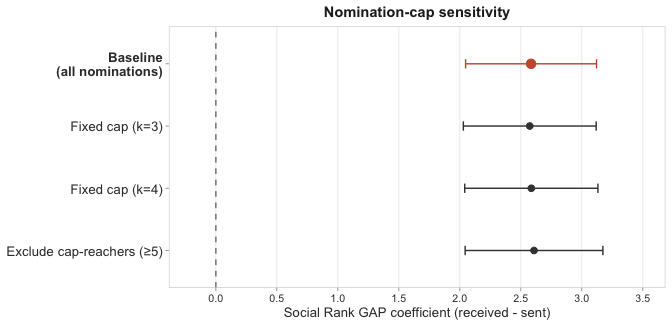

In [ ]:
# Figure S26: Social Rank GAP coefficient under each nomination-cap
# construction
figure_s26 <- table_s36 %>%
  mutate(label = c("Baseline\n(all nominations)", "Fixed cap (k=3)", "Fixed cap (k=4)",
                   "Exclude cap-reachers (\u22655)"),
         label = fct_rev(fct_inorder(label)),
         baseline = row_number() == 1) %>%
  ggplot(aes(estimate, label, color = baseline)) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey50") +
  geom_errorbarh(aes(xmin = estimate - 1.96 * se, xmax = estimate + 1.96 * se), height = 0.15) +
  geom_point(aes(size = baseline)) +
  # The baseline in orange and larger, bold baseline label
  scale_color_manual(values = c(`FALSE` = "grey25", `TRUE` = color_highlight)) +
  scale_size_manual(values = c(`FALSE` = 2, `TRUE` = 3)) +
  scale_x_continuous(limits = c(-0.2, 3.5), breaks = seq(0, 3.5, 0.5)) +
  labs(title = "Nomination-cap sensitivity", x = "Social Rank GAP coefficient (received - sent)", y = NULL) +
  theme_si(10) +
  theme(plot.title = element_text(hjust = 0.5), plot.title.position = "panel",
        axis.text.y = element_text(face = c("plain", "plain", "plain", "bold"), size = 10),
        panel.grid.major.x = element_line(color = "grey92", linewidth = 0.3),
        panel.grid.major.y = element_blank())
figure_s26

## 8.4 Classroom size (Figure S27)

### Number of classrooms in each size group

In [ ]:
# 8.4 Does the slope differ by classroom size? Size terciles and a continuous
# interaction (the main effect of size is absorbed by the fixed effects).
dyads <- dyads %>%
  group_by(class_id) %>% mutate(class_size = n_distinct(sender_id)) %>% ungroup() %>%
  mutate(size_group = cut(class_size, c(0, 15, 21, 39), labels = c("Small (<=15)", "Medium (16-21)", "Large (>21)")))

dyads %>% distinct(class_id, size_group) %>% count(size_group)

size_group,n
Small (<=15),16
Medium (16-21),14
Large (>21),15


### Social Rank GAP slope by classroom size group

In [ ]:
size_slopes <- dyads %>%
  group_by(size_group) %>%
  group_modify(~ term_estimate(preferred_model(.x))) %>% ungroup()
size_slopes

size_group,estimate,se,p_value
Small (<=15),1.987877,0.6666323,0.0093082
Medium (16-21),2.824818,0.5507177,0.0001935
Large (>21),2.636798,0.3660777,0.0000045


### Joint test of differences across size groups

In [ ]:
size_interaction <- preferred_model(dyads, rhs = "rank_gap * size_group")
lfe::waldtest(size_interaction, grep("rank_gap:size_group", names(coef(size_interaction))))[["p.F"]]
## [1] 0.5935522

### Interaction with classroom size as a continuous measure

In [ ]:
term_estimate(preferred_model(dyads, rhs = "rank_gap * class_size"), "rank_gap:class_size")

estimate,se,p_value
0.0239172,0.0256327,0.355873


In [ ]:
# Figure S27: observed Cooperation GAP by sender and receiver rank quartile,
# in small, medium and large classrooms. The three heatmaps share one
# drawing, written as a function.
quartile_cuts <- quantile(c(dyads$sender_rank, dyads$receiver_rank), c(0.25, 0.5, 0.75))
size_titles <- size_slopes %>%
  left_join(dyads %>% distinct(class_id, size_group) %>% count(size_group, name = "classes"), by = "size_group") %>%
  mutate(title = c("A. Small (n \u2264 15)", "B. Medium (16\u201321)", "C. Large (n > 21)"))

cells <- dyads %>%
  mutate(sender_q   = findInterval(sender_rank, quartile_cuts, left.open = TRUE) + 1,
         receiver_q = findInterval(receiver_rank, quartile_cuts, left.open = TRUE) + 1) %>%
  group_by(size_group, sender_q, receiver_q) %>%
  summarise(observed = mean(coop_gap), .groups = "drop")

# one heatmap per size group, with the slope and number of classes below the title
size_panel <- function(i) {
  info <- size_titles[i, ]
  cells %>% filter(size_group == info$size_group) %>%
    ggplot(aes(factor(receiver_q, labels = quartile_labels), factor(sender_q, labels = quartile_labels),
               fill = observed)) +
    geom_tile(color = "white", linewidth = 0.6) +
    geom_text(aes(label = sprintf("%+.2f", observed), color = abs(observed) > 1.1),
              fontface = "bold", size = 3.4) +
    scale_fill_coop_gap() +
    scale_color_manual(values = c(`FALSE` = "grey15", `TRUE` = "white"), guide = "none") +
    scale_x_discrete(expand = c(0, 0)) + scale_y_discrete(expand = c(0, 0)) +
    coord_fixed() +
    labs(title = info$title,
         subtitle = bquote(hat(beta) == .(sprintf("%.2f", info$estimate)) %.% .(info$classes) ~ "classes"),
         x = "Receiver's rank quartile", y = if (i == 1) "Sender's rank quartile" else NULL) +
    theme_heatmap(9) +
    guides(fill = guide_colorbar(title.position = "right",
                                 title.theme = element_text(angle = 90, size = 8)))
}

One heatmap on its own (small classrooms):

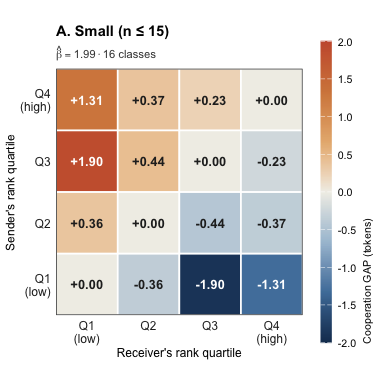

In [ ]:
size_panel(1)

The three heatmaps, as in the SI:

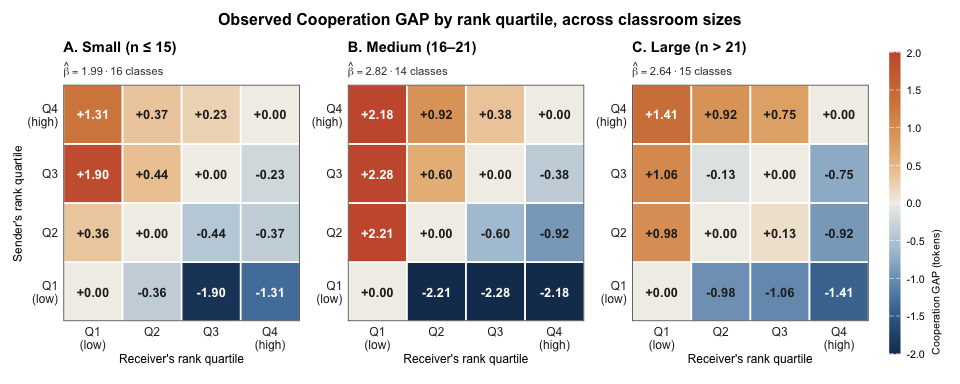

In [ ]:
figure_s27 <- wrap_plots(map(seq_len(nrow(size_titles)), size_panel), nrow = 1, guides = "collect") +
  figure_title("Observed Cooperation GAP by rank quartile, across classroom sizes", size = 12)
figure_s27

## 8.5 Temporal robustness (Table S37)

In [ ]:
# 8.5 Does the slope change over the session?
#   progress_c          the sender's progress, centered (-0.5 to 0.5)
#   decile differences  receiver-minus-sender indicators of progress deciles
dyads <- dyads %>%
  group_by(sender_id) %>% arrange(round, .by_group = TRUE) %>%
  mutate(order = row_number(), progress = (order - 1) / (n() - 1),
         progress_c = progress - 0.5,
         decile = pmin(pmax(ceiling(progress * 10), 1), 10)) %>%
  ungroup()

# decile of the receiver in this same encounter
receiver_decile <- dyads %>% select(class_id, sender_id = receiver_id, receiver_id = sender_id,
                                    receiver_decile = decile)
dyads <- dyads %>% left_join(receiver_decile, by = c("class_id", "sender_id", "receiver_id"))
for (k in 2:10) {
  dyads[[paste0("decile_diff_", k)]] <- (dyads$receiver_decile == k) - (dyads$decile == k)
}
decile_controls <- paste(paste0("decile_diff_", 2:10), collapse = " + ")
non_mutual <- dyads %>% filter(friendship %in% c("Non-friends", "Mutual"))

temporal_models <- list(
  "(1) main"                    = preferred_model(dyads),
  "(2) sender linear trends"    = preferred_model(dyads, fixed_effects = "sender_id + class_round + sender_id:progress"),
  "(3) progress deciles"        = preferred_model(dyads, rhs = paste("rank_gap +", decile_controls)),
  "(4) gap x progress"          = preferred_model(dyads, rhs = "rank_gap * progress_c"),
  "(5) non-friends, x progress" = preferred_model(filter(dyads, friendship == "Non-friends"), rhs = "rank_gap * progress_c"),
  "(6) pooled"                  = preferred_model(non_mutual, rhs = "rank_gap * mutual"),
  "(7) pooled + deciles"        = preferred_model(non_mutual, rhs = paste0("rank_gap * mutual + (", decile_controls, ") * mutual")),
  "(8) pooled x progress"       = preferred_model(non_mutual, rhs = "rank_gap * mutual * progress_c")
)

table_s37 <- imap_dfr(temporal_models, function(fit, name) {
  summary(fit)$coefficients %>% as_tibble(rownames = "term") %>%
    filter(str_detect(term, "rank_gap")) %>%
    transmute(model = name, term, estimate = Estimate, se = `Cluster s.e.`, p_value = `Pr(>|t|)`, n = fit$N)
})
table_s37 %>% mutate(across(where(is.double), ~ round(.x, 3)))

model,term,estimate,se,p_value,n
(1) main,rank_gap,2.584,0.274,0.000,17804
(2) sender linear trends,rank_gap,2.551,0.271,0.000,17804
(3) progress deciles,rank_gap,2.581,0.275,0.000,17804
(4) gap x progress,rank_gap,2.567,0.270,0.000,17804
(4) gap x progress,rank_gap:progress_c,0.598,0.478,0.217,17804
"(5) non-friends, x progress",rank_gap,2.532,0.275,0.000,13916
"(5) non-friends, x progress",rank_gap:progress_c,0.534,0.582,0.364,13916
(6) pooled,rank_gap,2.592,0.267,0.000,15204
(6) pooled,rank_gap:mutual,-1.674,0.557,0.004,15204
(7) pooled + deciles,rank_gap,2.586,0.267,0.000,15204


## 8.6 Lagged placebo (Tables S38–S39)

### Table S38. Previous decision’s rank gap in the full sample

In [ ]:
# 8.6 Placebo: the rank gap the child faced in her previous decision should
# not predict today's Cooperation GAP once sender and class-round FE are in.
dyads <- dyads %>%
  group_by(sender_id) %>% arrange(order, .by_group = TRUE) %>%
  mutate(lagged_rank_gap = lag(rank_gap)) %>% ungroup()

lagged <- dyads %>% filter(!is.na(lagged_rank_gap))
fe_placebo <- fe_progression(lagged, formula_rhs = "lagged_rank_gap")
regression_table(fe_placebo, terms = "lagged_rank_gap")

row,(1),(2),(3),(4),(5)
lagged_rank_gap,1.512***,1.512***,0.290,0.290,0.295
,(0.103),(0.181),(0.288),(0.288),(0.290)
Observations,"16,945","16,945","16,945","16,945","16,945"
R2,0.013,0.013,0.259,0.259,0.264
Adj. R2,0.013,0.010,0.219,0.217,0.174


### Table S39. Placebo estimates by sample and token filter

In [ ]:
placebo_samples <- list(
  "All"                    = list(lagged, "coop_gap"),
  "All (filtered)"         = list(lagged, "coop_gap_filtered"),
  "Mutual"                 = list(filter(lagged, friendship == "Mutual"), "coop_gap"),
  "Mutual (filtered)"      = list(filter(lagged, friendship == "Mutual"), "coop_gap_filtered"),
  "Non-friends"            = list(filter(lagged, friendship == "Non-friends"), "coop_gap"),
  "Non-friends (filtered)" = list(filter(lagged, friendship == "Non-friends"), "coop_gap_filtered")
)
table_s39 <- imap_dfr(placebo_samples, function(s, name) {
  d <- s[[1]] %>% filter(!is.na(.data[[s[[2]]]]))
  fit <- preferred_model(d, outcome = s[[2]], rhs = "lagged_rank_gap")
  term_estimate(fit, "lagged_rank_gap") %>% mutate(sample = name, n = nrow(d), .before = 1)
})
table_s39

sample,n,estimate,se,p_value
All,16945,0.2952552,0.2897583,0.3137873
All (filtered),4358,-0.7383623,0.3923966,0.0665060
Mutual,1228,0.8190812,1.2947451,0.5302562
Mutual (filtered),541,7.2978025,3.6523657,0.0562658
Non-friends,13245,0.2427858,0.3085534,0.4355866
Non-friends (filtered),3116,-0.6471377,0.6039127,0.2897537


## 8.7 Sex and grade level (Tables S40–S51)

The models compare the observed and filtered Cooperation GAP within each
sample. The sex tables vary the controls and interactions for sender and
receiver sex. The grade tables compare a pooled model with grade
indicators and separate models for grades 3, 4, and 5.

In [ ]:
# The SI reports separate samples and the same model layouts for observed
# and filtered transfers. Filter before fitting or forming subgroups.
dyads <- dyads %>%
  left_join(students %>% select(sender_id = student_id, sender_female = female, grade), by = "sender_id") %>%
  left_join(students %>% select(receiver_id = student_id, receiver_female = female), by = "receiver_id")

sex_models <- function(data, outcome) {
  data <- filter(data, !is.na(.data[[outcome]]))
  class_sender <- "class_id + sender_id"
  girls <- filter(data, sender_female == 1)
  boys <- filter(data, sender_female == 0)
  list(
    "(1) All" = preferred_model(data, outcome, "rank_gap", "class_id"),
    "(2) Sender sex" = preferred_model(data, outcome, "rank_gap + sender_female", "class_id"),
    "(3) Receiver sex" = preferred_model(data, outcome, "rank_gap + receiver_female", class_sender),
    "(4) Interactions" = preferred_model(data, outcome, "rank_gap * sender_female * receiver_female", "class_id"),
    "(5) Girls" = preferred_model(girls, outcome, "rank_gap", class_sender),
    "(6) Girls + receiver sex" = preferred_model(girls, outcome, "rank_gap + receiver_female", class_sender),
    "(7) Boys" = preferred_model(boys, outcome, "rank_gap", class_sender),
    "(8) Boys + receiver sex" = preferred_model(boys, outcome, "rank_gap + receiver_female", class_sender)
  )
}

grade_models <- function(data, outcome) {
  data <- filter(data, !is.na(.data[[outcome]])) %>%
    mutate(grade4 = as.integer(grade == 4), grade5 = as.integer(grade == 5))
  pooled <- quiet_felm(as.formula(paste(outcome, "~ rank_gap + grade4 + grade5 | 0 | 0 | 0")), data)
  by_grade <- map(3:5, function(level) {
    sample <- filter(data, grade == level)
    list(preferred_model(sample, outcome, "rank_gap", "class_id"),
         preferred_model(sample, outcome, "rank_gap", "class_id + sender_id"))
  })
  c(list(pooled), flatten(by_grade)) %>%
    set_names(c("(1) Pooled", "(2) Grade 3", "(3) Grade 3 + sender FE",
                "(4) Grade 4", "(5) Grade 4 + sender FE",
                "(6) Grade 5", "(7) Grade 5 + sender FE"))
}

subgroup_tables <- expand_grid(by = c("sex", "grade"),
                               sample = c("All dyads", "Mutual friends", "Non-friends"),
                               outcome = c("coop_gap", "coop_gap_filtered")) %>%
  mutate(table = pmap(list(by, sample, outcome), function(by, sample, outcome) {
    d <- switch(sample, "All dyads" = dyads,
                "Mutual friends" = filter(dyads, friendship == "Mutual"),
                "Non-friends" = filter(dyads, friendship == "Non-friends"))
    models <- if (by == "sex") sex_models(d, outcome) else grade_models(d, outcome)
    regression_table(models)
  }))

subgroup_table <- function(grouping, friendship_sample, outcome_name) {
  subgroup_tables %>%
    filter(by == grouping, sample == friendship_sample, outcome == outcome_name) %>%
    pull(table) %>% pluck(1)
}

### By sex

#### Table S40. All dyads, observed tokens

In [ ]:
knitr::kable(subgroup_table("sex", "All dyads", "coop_gap"))

row,(1) All,(2) Sender sex,(3) Receiver sex,(4) Interactions,(5) Girls,(6) Girls + receiver sex,(7) Boys,(8) Boys + receiver sex
rank_gap,2.584***,2.586***,2.592***,2.259***,2.818***,2.822***,2.271***,2.277***
,(0.272),(0.270),(0.270),(0.411),(0.288),(0.287),(0.373),(0.371)
sender_female,,0.105,,0.101,,,,
,,(0.269),,(0.258),,,,
receiver_female,,,-0.095,-0.101,,-0.079,,-0.109
,,,(0.258),(0.258),,(0.266),,(0.254)
rank_gap:sender_female,,,,0.369,,,,
,,,,(0.346),,,,
rank_gap:receiver_female,,,,0.369,,,,
,,,,(0.346),,,,


#### Table S41. All dyads, filtered tokens

In [ ]:
knitr::kable(subgroup_table("sex", "All dyads", "coop_gap_filtered"))

row,(1) All,(2) Sender sex,(3) Receiver sex,(4) Interactions,(5) Girls,(6) Girls + receiver sex,(7) Boys,(8) Boys + receiver sex
rank_gap,3.093***,3.094***,3.185***,3.443***,2.850***,2.847***,3.692***,3.710***
,(0.469),(0.465),(0.449),(0.577),(0.498),(0.490),(0.606),(0.591)
sender_female,,0.247,,0.248,,,,
,,(0.239),,(0.237),,,,
receiver_female,,,-0.202,-0.248,,-0.237,,-0.180
,,,(0.239),(0.237),,(0.248),,(0.253)
rank_gap:sender_female,,,,0.106,,,,
,,,,(0.716),,,,
rank_gap:receiver_female,,,,0.106,,,,
,,,,(0.716),,,,


#### Table S42. Mutual friends, observed tokens

In [ ]:
knitr::kable(subgroup_table("sex", "Mutual friends", "coop_gap"))

row,(1) All,(2) Sender sex,(3) Receiver sex,(4) Interactions,(5) Girls,(6) Girls + receiver sex,(7) Boys,(8) Boys + receiver sex
rank_gap,0.293,0.293,1.264,0.857,1.050,1.010,1.470,1.422
,(0.693),(0.694),(0.784),(1.157),(0.750),(0.787),(1.545),(1.531)
sender_female,,0.025,,0.204,,,,
,,(0.128),,(0.695),,,,
receiver_female,,,-0.188,-0.204,,0.202,,-0.492
,,,(0.596),(0.695),,(0.796),,(0.669)
rank_gap:sender_female,,,,0.935,,,,
,,,,(2.670),,,,
rank_gap:receiver_female,,,,0.935,,,,
,,,,(2.670),,,,


#### Table S43. Mutual friends, filtered tokens

In [ ]:
knitr::kable(subgroup_table("sex", "Mutual friends", "coop_gap_filtered"))

row,(1) All,(2) Sender sex,(3) Receiver sex,(4) Interactions,(5) Girls,(6) Girls + receiver sex,(7) Boys,(8) Boys + receiver sex
rank_gap,-0.593,-0.588,-0.400,-0.058,0.310,-0.053,-1.388,-1.334
,(0.607),(0.608),(1.052),(1.267),(1.066),(1.147),(1.767),(1.741)
sender_female,,0.175,,0.783,,,,
,,(0.233),,(1.321),,,,
receiver_female,,,1.945,-0.783,,4.009**,,0.576
,,,(1.686),(1.321),,(1.465),,(2.290)
rank_gap:sender_female,,,,-0.687,,,,
,,,,(6.088),,,,
rank_gap:receiver_female,,,,-0.687,,,,
,,,,(6.088),,,,


#### Table S44. Non-friends, observed tokens

In [ ]:
knitr::kable(subgroup_table("sex", "Non-friends", "coop_gap"))

row,(1) All,(2) Sender sex,(3) Receiver sex,(4) Interactions,(5) Girls,(6) Girls + receiver sex,(7) Boys,(8) Boys + receiver sex
rank_gap,2.574***,2.577***,2.575***,2.296***,2.771***,2.773***,2.269***,2.260***
,(0.264),(0.261),(0.270),(0.402),(0.298),(0.297),(0.423),(0.426)
sender_female,,0.127,,0.104,,,,
,,(0.306),,(0.253),,,,
receiver_female,,,-0.073,-0.104,,-0.021,,-0.136
,,,(0.267),(0.253),,(0.274),,(0.269)
rank_gap:sender_female,,,,0.166,,,,
,,,,(0.389),,,,
rank_gap:receiver_female,,,,0.166,,,,
,,,,(0.389),,,,


#### Table S45. Non-friends, filtered tokens

In [ ]:
knitr::kable(subgroup_table("sex", "Non-friends", "coop_gap_filtered"))

row,(1) All,(2) Sender sex,(3) Receiver sex,(4) Interactions,(5) Girls,(6) Girls + receiver sex,(7) Boys,(8) Boys + receiver sex
rank_gap,3.260***,3.261***,3.223***,3.841***,2.971***,2.976***,3.682***,3.680***
,(0.462),(0.456),(0.490),(0.610),(0.541),(0.534),(0.733),(0.736)
sender_female,,0.238,,0.194,,,,
,,(0.286),,(0.232),,,,
receiver_female,,,-0.126,-0.194,,-0.198,,-0.044
,,,(0.221),(0.232),,(0.240),,(0.243)
rank_gap:sender_female,,,,-0.601,,,,
,,,,(0.779),,,,
rank_gap:receiver_female,,,,-0.601,,,,
,,,,(0.779),,,,


### By grade

#### Table S46. All dyads, observed tokens

In [ ]:
knitr::kable(subgroup_table("grade", "All dyads", "coop_gap"))

row,(1) Pooled,(2) Grade 3,(3) Grade 3 + sender FE,(4) Grade 4,(5) Grade 4 + sender FE,(6) Grade 5,(7) Grade 5 + sender FE
(Intercept),0.000,,,,,,
,(0.066),,,,,,
rank_gap,2.584***,2.452***,2.454***,3.117***,3.127***,1.884**,1.878**
,(0.098),(0.297),(0.293),(0.427),(0.424),(0.600),(0.604)
grade4,-0.000,,,,,,
,(0.085),,,,,,
grade5,-0.000,,,,,,
,(0.093),,,,,,
Observations,"17,804","4,912","4,912","7,740","7,740","5,152","5,152"
R2,0.037,0.033,0.256,0.054,0.290,0.020,0.260


#### Table S47. All dyads, filtered tokens

In [ ]:
knitr::kable(subgroup_table("grade", "All dyads", "coop_gap_filtered"))

row,(1) Pooled,(2) Grade 3,(3) Grade 3 + sender FE,(4) Grade 4,(5) Grade 4 + sender FE,(6) Grade 5,(7) Grade 5 + sender FE
(Intercept),-0.000,,,,,,
,(0.134),,,,,,
rank_gap,3.093***,3.573**,3.819**,3.084***,2.861***,2.568**,3.038***
,(0.197),(1.073),(1.027),(0.653),(0.611),(0.661),(0.626)
grade4,0.000,,,,,,
,(0.168),,,,,,
grade5,0.000,,,,,,
,(0.188),,,,,,
Observations,"4,590","1,226","1,226","2,100","2,100","1,264","1,264"
R2,0.051,0.064,0.280,0.051,0.291,0.037,0.295


#### Table S48. Mutual friends, observed tokens

In [ ]:
knitr::kable(subgroup_table("grade", "Mutual friends", "coop_gap"))

row,(1) Pooled,(2) Grade 3,(3) Grade 3 + sender FE,(4) Grade 4,(5) Grade 4 + sender FE,(6) Grade 5,(7) Grade 5 + sender FE
(Intercept),-0.000,,,,,,
,(0.233),,,,,,
rank_gap,0.293,1.756,2.230,-0.002,1.105,-1.326,0.275
,(0.404),(1.003),(1.259),(0.945),(1.148),(1.802),(1.888)
grade4,0.000,,,,,,
,(0.298),,,,,,
grade5,0.000,,,,,,
,(0.312),,,,,,
Observations,"1,288",336,336,530,530,422,422
R2,0.000,0.023,0.653,0.000,0.675,0.006,0.609


#### Table S49. Mutual friends, filtered tokens

In [ ]:
knitr::kable(subgroup_table("grade", "Mutual friends", "coop_gap_filtered"))

row,(1) Pooled,(2) Grade 3,(3) Grade 3 + sender FE,(4) Grade 4,(5) Grade 4 + sender FE,(6) Grade 5,(7) Grade 5 + sender FE
(Intercept),-0.000,,,,,,
,(0.361),,,,,,
rank_gap,-0.593,1.486,-1.169,-0.877,-0.779,-2.337†,0.889
,(0.530),(1.153),(1.509),(0.798),(1.154),(1.168),(2.325)
grade4,0.000,,,,,,
,(0.425),,,,,,
grade5,0.000,,,,,,
,(0.451),,,,,,
Observations,548,102,102,264,264,182,182
R2,0.002,0.026,0.865,0.005,0.743,0.024,0.729


#### Table S50. Non-friends, observed tokens

In [ ]:
knitr::kable(subgroup_table("grade", "Non-friends", "coop_gap"))

row,(1) Pooled,(2) Grade 3,(3) Grade 3 + sender FE,(4) Grade 4,(5) Grade 4 + sender FE,(6) Grade 5,(7) Grade 5 + sender FE
(Intercept),0.000,,,,,,
,(0.077),,,,,,
rank_gap,2.574***,2.481***,2.341***,3.040***,3.145***,1.940**,1.874**
,(0.110),(0.279),(0.341),(0.441),(0.433),(0.521),(0.535)
grade4,0.000,,,,,,
,(0.097),,,,,,
grade5,-0.000,,,,,,
,(0.106),,,,,,
Observations,"13,916","3,726","3,726","6,130","6,130","4,060","4,060"
R2,0.038,0.032,0.263,0.054,0.306,0.023,0.283


#### Table S51. Non-friends, filtered tokens

In [ ]:
knitr::kable(subgroup_table("grade", "Non-friends", "coop_gap_filtered"))

row,(1) Pooled,(2) Grade 3,(3) Grade 3 + sender FE,(4) Grade 4,(5) Grade 4 + sender FE,(6) Grade 5,(7) Grade 5 + sender FE
(Intercept),-0.000,,,,,,
,(0.160),,,,,,
rank_gap,3.260***,3.418**,3.737**,3.330***,3.016***,2.963**,2.932**
,(0.233),(0.949),(0.908),(0.723),(0.695),(0.724),(0.855)
grade4,0.000,,,,,,
,(0.204),,,,,,
grade5,0.000,,,,,,
,(0.228),,,,,,
Observations,"3,302",920,920,"1,488","1,488",894,894
R2,0.056,0.054,0.314,0.060,0.334,0.052,0.348


## 8.8 Alternative Social Rank constructions (Figure S28)

In [ ]:
# 8.8 The preferred model with the rank gap from each alternative
# construction of Social Rank (built in S4)
alternative_ranks <- read_csv(here("data", "generated", "alternative_ranks.csv"), show_col_types = FALSE)
alternative_labels <- c(social_rank          = "Pop. Social Rank\n(Affine transform)",
                        rank_pn_centrality   = "Signed PN centrality",
                        rank_net_nominations = "Net nominations",
                        rank_pr_minus_neg_in = "Pos. PageRank -\nneg. indegree",
                        rank_two_layer       = "Two-layer PageRank",
                        rank_positive_only   = "Positive-only PageRank")

gap_with <- function(measure) {
  r <- setNames(alternative_ranks[[measure]], alternative_ranks$student_id)
  r[as.character(dyads$sender_id)] - r[as.character(dyads$receiver_id)]
}

# Five samples as in the SI figure, all with the preferred specification.
# One-sided friendships are seen from the receiver ("alter declares") or from
# the sender ("ego declares").
robustness_samples <- c("A. All dyads", "B. Non-friends", "C. Mutual friends",
                        "D. Alter declares", "E. Ego declares")

rank_robustness <- expand_grid(measure = names(alternative_labels), sample = robustness_samples) %>%
  mutate(result = map2(measure, sample, function(m, s) {
    d <- dyads %>% mutate(rank_gap = gap_with(m))
    d <- switch(s,
                "A. All dyads"      = d,
                "B. Non-friends"    = filter(d, friendship == "Non-friends"),
                "C. Mutual friends" = filter(d, friendship == "Mutual"),
                "D. Alter declares" = filter(d, friendship == "Receiver declares"),
                "E. Ego declares"   = filter(d, friendship == "Sender declares"))
    term_estimate(preferred_model(d))
  })) %>%
  unnest(result) %>%
  mutate(primary = measure == "social_rank",
         measure = factor(alternative_labels[measure], levels = rev(alternative_labels)))

rank_robustness %>% select(measure, sample, estimate) %>%
  pivot_wider(names_from = sample, values_from = estimate)

measure,A. All dyads,B. Non-friends,C. Mutual friends,D. Alter declares,E. Ego declares
Pop. Social Rank (Affine transform),2.583957,2.561512,1.0692579,3.8144865,-1.0430772
Signed PN centrality,2.651142,2.587113,1.6390939,4.4360531,-0.9197614
Net nominations,2.681388,2.628095,1.8536507,4.3184985,-0.9329694
Pos. PageRank - neg. indegree,2.467239,2.417555,1.5936074,3.8164066,-1.2799587
Two-layer PageRank,2.654337,2.623596,1.5537075,4.2029211,-0.9682593
Positive-only PageRank,1.420378,1.387366,0.6653481,0.6428967,-1.0068310


The figure as in the SI, with its colors, labels and legends (code from
the script):

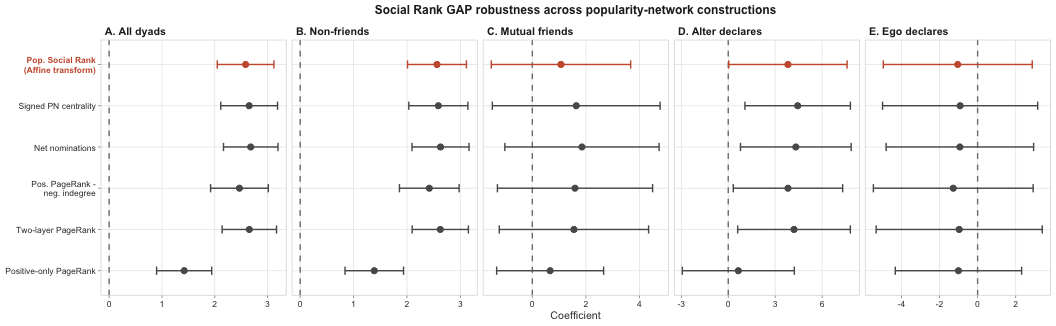

In [ ]:
# Figure S28: Social Rank GAP coefficient for each rank construction and sample
figure_s28 <- ggplot(rank_robustness, aes(estimate, measure, color = primary)) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey50") +
  geom_errorbarh(aes(xmin = estimate - 1.96 * se, xmax = estimate + 1.96 * se), height = 0.2) +
  geom_point(size = 1.8) +
  facet_wrap(~ sample, nrow = 1, scales = "free_x") +
  # The primary Social Rank in orange, with a bold label
  scale_color_manual(values = c(`FALSE` = "grey35", `TRUE` = color_highlight)) +
  labs(title = "Social Rank GAP robustness across popularity-network constructions",
       x = "Coefficient", y = NULL) +
  theme_si(8) +
  theme(plot.title = element_text(hjust = 0.5), plot.title.position = "panel",
        axis.text.y = element_text(color = rev(c(color_highlight, rep(color_text, 5))),
                                   face = rev(c("bold", rep("plain", 5)))),
        panel.grid.major.x = element_line(color = "grey92", linewidth = 0.3))
figure_s28

## 8.9 Rank from affiliation networks (Table S52)

### Table S52. Regression estimates using affiliation-based ranks

In [ ]:
# 8.9 Rank from affiliation networks instead of popularity: PageRank of
# "most like to hang out" (Q1), Q1 minus "least like to hang out" (Q2)
# (standardized PageRanks), and PageRank of best friends (Q3)
pagerank_of <- function(nominations) {
  dyads %>%
    transmute(class_id, from = as.character(sender_id), to = as.character(receiver_id), w = nominations) %>%
    group_by(class_id) %>%
    group_modify(function(e, key) {
      pr <- page_rank(graph_from_data_frame(e %>% filter(w > 0) %>% select(from, to),
                                            vertices = data.frame(name = unique(c(e$from, e$to)))))$vector
      tibble(student_id = as.numeric(names(pr)), pr = pr)
    }) %>% ungroup()
}

z <- function(x) (x - mean(x)) / sd(x)
affiliation_ranks <- pagerank_of(dyads$nom_q1) %>% rename(pr_q1 = pr) %>%
  left_join(pagerank_of(dyads$nom_q2) %>% rename(pr_q2 = pr), by = c("class_id", "student_id")) %>%
  left_join(pagerank_of(dyads$nom_q3) %>% rename(pr_q3 = pr), by = c("class_id", "student_id")) %>%
  group_by(class_id) %>%
  mutate(rank_hangout        = (pr_q1 - min(pr_q1)) / (max(pr_q1) - min(pr_q1)),
         rank_hangout_minus  = { x <- z(pr_q1) - z(pr_q2); (x - min(x)) / (max(x) - min(x)) },
         rank_best_friend    = (pr_q3 - min(pr_q3)) / (max(pr_q3) - min(pr_q3))) %>%
  ungroup() %>%
  left_join(students %>% select(student_id, social_rank), by = "student_id")

affiliation_labels <- c(social_rank = "Pop. Social Rank (primary)",
                        rank_hangout = "Most-like-to-hang-out PageRank",
                        rank_hangout_minus = "Most-minus-least hang-out PageRank",
                        rank_best_friend = "Best-friend PageRank")

table_s52 <- expand_grid(measure = names(affiliation_labels),
                         sample = c("All dyads", "Non-friends", "Mutual friends")) %>%
  mutate(result = map2(measure, sample, function(m, s) {
    r <- setNames(affiliation_ranks[[m]], affiliation_ranks$student_id)
    d <- dyads %>% mutate(rank_gap = r[as.character(sender_id)] - r[as.character(receiver_id)])
    d <- switch(s, "All dyads" = d, "Non-friends" = filter(d, friendship == "Non-friends"),
                "Mutual friends" = filter(d, friendship == "Mutual"))
    term_estimate(preferred_model(d)) %>% mutate(sd_gap = sd(d$rank_gap))
  })) %>%
  unnest(result) %>%
  mutate(measure = affiliation_labels[measure])

table_s52 %>%
  mutate(cell = sprintf("%.3f%s (%.3f)", estimate, si_stars(p_value), se)) %>%
  select(measure, sample, cell) %>%
  pivot_wider(names_from = sample, values_from = cell)

measure,All dyads,Non-friends,Mutual friends
Pop. Social Rank (primary),2.584*** (0.274),2.562*** (0.281),1.069 (1.327)
Most-like-to-hang-out PageRank,1.279*** (0.267),1.117*** (0.284),-0.887 (1.178)
Most-minus-least hang-out PageRank,1.492*** (0.294),1.345*** (0.300),-1.275 (1.715)
Best-friend PageRank,1.286*** (0.302),1.179** (0.337),1.617 (1.452)


### Agreement with the popularity-based Social Rank

Each entry is the median of the classroom-level Spearman correlations.

In [ ]:
# agreement with the primary rank (median within-class Spearman)
affiliation_ranks %>%
  group_by(class_id) %>%
  summarise(across(c(rank_hangout, rank_hangout_minus, rank_best_friend),
                   ~ cor(.x, social_rank, method = "spearman"))) %>%
  summarise(across(-class_id, median))

rank_hangout,rank_hangout_minus,rank_best_friend
0.4942252,0.4899733,0.5152298


In [ ]:
save_table(regression_table(fe_filtered_all, terms = "rank_gap"),    "S8_table_s25_filtered_all")
save_table(regression_table(fe_filtered_non, terms = "rank_gap"),    "S8_table_s26_filtered_non_friends")
save_table(regression_table(fe_filtered_mutual, terms = "rank_gap"), "S8_table_s27_filtered_mutual")
save_table(regression_table(fe_filtered_pooled, terms = c("rank_gap", "mutual", "rank_gap:mutual")), "S8_table_s28_filtered_pooled")
save_table(regression_table(fe_filtered_lh, terms = "rank_gap"),     "S8_table_s29_filtered_low_to_high")
save_table(regression_table(fe_filtered_hl, terms = "rank_gap"),     "S8_table_s29_filtered_high_to_low")
save_table(table_s30, "S8_table_s30_filtered_contrast")
save_table(threshold_sensitivity, "S8_tables_s31_s34_thresholds")
save_table(asymmetric_thresholds, "S8_table_s35_asymmetric_thresholds")
save_table(table_s36, "S8_table_s36_nomination_cap")
save_table(size_slopes, "S8_class_size_slopes")
save_table(table_s37, "S8_table_s37_temporal")
save_table(regression_table(fe_placebo, terms = "lagged_rank_gap"), "S8_table_s38_placebo")
save_table(table_s39, "S8_table_s39_placebo_samples")
pwalk(subgroup_tables, function(by, sample, outcome, table) {
  save_table(table, paste("S8_subgroup", by, str_replace_all(tolower(sample), "[^a-z]+", "_"), outcome, sep = "_"))
})
save_table(rank_robustness, "S8_rank_constructions")
save_table(table_s52, "S8_table_s52_affiliation_ranks")
save_si_figure(figure_s25, "S8_figure_s25_filtered", 6.5, 7.6)
save_si_figure(figure_asymmetric_thresholds, "S8_figure_asymmetric_thresholds", 9, 6)
save_si_figure(figure_s26, "S8_figure_s26_nomination_cap", 7, 3.4)
save_si_figure(figure_s27, "S8_figure_s27_class_size", 10, 4)
save_si_figure(figure_s28, "S8_figure_s28_rank_constructions", 11, 3.4)